# Буткемп, день 26 — queue depletion, cancellations, hidden liquidity

Задание: разметить переходы touch-состояния, разложить потоки на trade / cancel / add по уровням, измерить depletion hazard, разделить отмены на repricing и fleeing, оценить hidden-liquidity ratio и собрать предиктор следующего перехода с проверкой на baseline и экономическим тестом.

Данные: Bybit BTCUSDT, 12:00–12:30 UTC 2026-07-01, полный L2-фид (640 223 апдейта) и трейды. Восстанавливаем стакан событие за событием, фиксируем состояние при каждом изменении touch: 77 475 переходов, медианная длительность 6.7 мс. Все признаки считаются только по прошлому (trailing 1 с); метка — следующий переход; последнее состояние цензурировано и выброшено; train/test — по времени, не случайно.

**Главный результат.** На этом сэмпле base rates `replenish 37% / hold 35% / deplete 22.5% / improve 5.4%`; доля отменённого объёма от снятого с уровня 99.7%, от выставленного — 38%; hazard падает с 40% в первые 50 мс после сделки до 18% после 1 с; fleeing-отмены дают лишь R²≈0.0002 к следующему движению; hidden-ratio по прокси «трейд больше показанного» — 1.8%, а не 12–30%. Предиктор следующего сдвига: queue imbalance даёт OOS R² 0.141, полный набор фичей — 0.146, то есть инкремент +0.005. Экономически сигнал выживает только при taker <1 bp (агрессивно) или maker 0.1 bp (пассивно); при retail 2 bp оба выражения убыточны. Это честный отрицательный результат для retail-тира, а не подтверждение стилизованных чисел слайдов.

## 1. Разметка переходов

Состояние — `(best_bid, bid_sz, best_ask, ask_sz)` после каждого L2-апдейта. Классы следующего изменения touch:
- **improve** — bid вырос или ask упал (кто-то встал впереди);
- **deplete** — bid упал или ask вырос (уровень очистился);
- **replenish** — цены те же, суммарный размер вырос;
- **hold** — остальное.

Длительность — время до следующего перехода; последнее состояние цензурировано. Никакого окна/бара/горизонта нет — метка это факт следующего события.

In [1]:
import duckdb,numpy as np,pandas as pd,heapq,time,matplotlib.pyplot as plt,warnings
from IPython.display import display
warnings.filterwarnings('ignore'); pd.set_option('display.width',220)
D='/Users/b.kotov/Downloads/'; con=duckdb.connect()
LO="TIMESTAMPTZ '2026-07-01 12:00:00+00'"; HI="TIMESTAMPTZ '2026-07-01 12:30:00+00'"
def dt_ns(x): return pd.DatetimeIndex(pd.to_datetime(x)).as_unit('ns').astype('int64').values
u=con.execute(f"""SELECT event_time,insertion_no,side,price,amount FROM read_parquet('{D}bybit_l2_20260701_20260703.parquet')
 WHERE symbol='BTCUSDT' AND event_time>={LO} AND event_time<{HI} ORDER BY event_time,insertion_no""").df()
tr=con.execute(f"""SELECT event_time,aggressor_side,price,amount FROM read_parquet('{D}bybit_anon_trades_20260701_20260703.parquet')
 WHERE symbol='BTCUSDT' AND event_time>={LO} AND event_time<{HI} ORDER BY event_time""").df()
tt=dt_ns(u.event_time); sd=u.side.values.astype(int); pr=np.round(u.price.values,1); am=u.amount.values
trt=dt_ns(tr.event_time); trs=tr.aggressor_side.values.astype(int); trp=np.round(tr.price.values,1); tra=tr.amount.values
t0=time.time(); bids={}; asks={}; hb=[]; ha=[]; states=[]; ev=[]; last_key=None; bb_prev=None; ba_prev=None
for i in range(len(u)):
    s=sd[i]; p=pr[i]; a=am[i]
    if s==1:
        old=bids.get(p,0.0)
        if a<=0: bids.pop(p,None); delta=-old
        else: bids[p]=a; delta=a-old
        heapq.heappush(hb,-p)
        while hb and (-hb[0] not in bids or bids.get(-hb[0],0)<=0): heapq.heappop(hb)
    else:
        old=asks.get(p,0.0)
        if a<=0: asks.pop(p,None); delta=-old
        else: asks[p]=a; delta=a-old
        heapq.heappush(ha,p)
        while ha and (ha[0] not in asks or asks.get(ha[0],0)<=0): heapq.heappop(ha)
    if not hb or not ha: continue
    bb=-hb[0]; ba=ha[0]; bsz=bids.get(bb,0.0); asz=asks.get(ba,0.0)
    bb_old=bb_prev; ba_old=ba_prev
    if delta!=0 and bb_old is not None and ba_old is not None:
        lev=int(round((bb_old-p)/0.1))+1 if s==1 else int(round((p-ba_old)/0.1))+1
        if 1<=lev<=5: ev.append((tt[i],s,lev,1 if delta>0 else -1,abs(delta),p))
    key=(bb,round(bsz,6),ba,round(asz,6))
    if key!=last_key:
        if last_key is not None:
            bp=sorted(bids)[-5:][::-1]; ap=sorted(asks)[:5]
            states.append((tt[i],bb,bsz,ba,asz,(bb+ba)/2,sum(bids[x] for x in bp),sum(asks[x] for x in ap)))
        last_key=key
    bb_prev=bb; ba_prev=ba
S=pd.DataFrame(states,columns=['t','bid','bsz','ask','asz','mid','b5','a5'])
S['bid_next']=S.bid.shift(-1); S['ask_next']=S.ask.shift(-1); S['bsz_next']=S.bsz.shift(-1); S['asz_next']=S.asz.shift(-1)
S['mid_next']=S.mid.shift(-1); S['dur']=S.t.shift(-1)-S.t
S=S.dropna(subset=['bid_next']).reset_index(drop=True)
def lab(r):
    if r.bid_next>r.bid or r.ask_next<r.ask: return 'improve'
    if r.bid_next<r.bid or r.ask_next>r.ask: return 'deplete'
    if r.bsz_next+r.asz_next>r.bsz+r.asz: return 'replenish'
    return 'hold'
S['label']=S.apply(lab,axis=1); S['dmove']=(S.mid_next-S.mid)/0.1; S['dur_ms']=S.dur/1e6
ev=np.array(ev,dtype=object); ev_t=ev[:,0].astype('int64'); ev_s=ev[:,1].astype(int); ev_l=ev[:,2].astype(int); ev_k=ev[:,3].astype(int); ev_sz=ev[:,4].astype(float); ev_p=ev[:,5].astype(float)
si=np.clip(np.searchsorted(S.t.values,trt,'right')-1,0,len(S)-1)
lev_t=np.where(trs==1,np.round((trp-S.ask.values[si])/0.1).astype(int)+1,np.round((S.bid.values[si]-trp)/0.1).astype(int)+1)
okt=(lev_t>=1)&(lev_t<=5); trt=trt[okt]; trs=trs[okt]; trl=lev_t[okt]; trz=tra[okt]
rows=[]
for j,t in enumerate(S.t.values):
    j1=np.searchsorted(ev_t,t,'right'); j0=np.searchsorted(ev_t,t-1_000_000_000,'left')
    ss=ev_s[j0:j1]; ll=ev_l[j0:j1]; kk=ev_k[j0:j1]; zz=ev_sz[j0:j1]; m1=ll==1
    q1=np.searchsorted(trt,t,'right'); q0=np.searchsorted(trt,t-1_000_000_000,'left')
    ts=trs[q0:q1]; tl=trl[q0:q1]; tz=trz[q0:q1]
    c2a=np.searchsorted(ev_t,t-200_000_000,'left'); c2b=np.searchsorted(ev_t,t,'right')
    m2=(ev_l[c2a:c2b]==1)&(ev_k[c2a:c2b]==-1)
    rows.append((zz[m1&(kk==1)&(ss==1)].sum(),zz[m1&(kk==1)&(ss==-1)].sum(),
                 zz[m1&(kk==-1)&(ss==1)].sum(),zz[m1&(kk==-1)&(ss==-1)].sum(),
                 tz[(tl==1)&(ts==-1)].sum(),tz[(tl==1)&(ts==1)].sum(),ev_sz[c2a:c2b][m2].sum()))
F=pd.DataFrame(rows,columns=['add_b','add_a','cxl_b','cxl_a','tr_b','tr_a','c200'])
S=pd.concat([S,F],axis=1)
S['qi']=(S.bsz-S.asz)/(S.bsz+S.asz); S['mlqi']=(S.b5-S.a5)/(S.b5+S.a5); S['size']=S.bsz+S.asz
S['trade']=S.tr_b+S.tr_a; S['cancel']=(S.cxl_b+S.cxl_a-S.trade).clip(lower=0); S['add']=S.add_b+S.add_a
S['cr']=S.trade/S['add'].clip(lower=1e-9); S['netflow']=(S['add']-S['cancel'])/S['size'].clip(lower=1e-9)
S['c200']=(S['c200']-S['trade']).clip(lower=0)
S['crate']=S['cancel']/S['size'].clip(lower=1e-9); S['trate']=S['trade']/S['size'].clip(lower=1e-9)
last_tr=np.full(len(S),np.nan)
for j,t in enumerate(S.t.values):
    q=np.searchsorted(trt,t,'right')-1
    if q>=0: last_tr[j]=(t-trt[q])/1e6
S['tst']=last_tr
S['tst']=S['tst'].fillna(S['tst'].max())
print('апдейтов %d, переходов %d, событий %d, трейдов %d, время %.1f c'%(len(u),len(S),len(ev),len(trt),time.time()-t0))
display(S.label.value_counts(normalize=True).rename('share').round(3).to_frame())
print('медианная длительность %.2f мс, p95 %.1f мс'%(S.dur_ms.median(),S.dur_ms.quantile(.95)))

апдейтов 640223, переходов 77475, событий 95227, трейдов 24989, время 15.6 c


,share
label,
replenish,0.369
hold,0.352
deplete,0.225
improve,0.054


медианная длительность 6.71 мс, p95 110.5 мс


## 2. Потоки, hazard, отмены и hidden liquidity

Flow-разложение по уровням: add — положительная дельта размера, cancel — отрицательная, trade — агрессивный объём на этом уровне. Доля отменённого от **снятого** объёма и от **выставленного** — две разные метрики; обе приводим, потому что слайды говорят «four fifths», но не уточняют знаменатель.

,level,add,cancel,trade,cancel/(cancel+trade),cancel/add
0,1,13706.786,12710.127,773.518,0.943,0.927
1,2,2587.499,1979.909,9.549,0.995,0.765
2,3,2035.071,1659.644,11.528,0.993,0.816
3,4,1901.444,1678.250,4.049,0.998,0.883
4,5,1880.999,1509.709,4.189,0.997,0.803


touch: cancel share of removed 0.943, of posted 0.927; trade share of posted 0.0564


,P(deplete),n
tb,,
0-50ms,0.223,32462
50-200ms,0.082,17162
200ms-1s,0.067,17422
>1s,0.049,2014


overall depletion rate 0.225; hazard ratio 0-50ms / >1s = 4.59


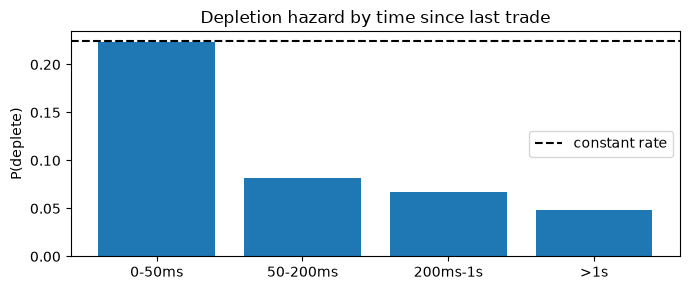

In [2]:
fl=pd.DataFrame({'side':ev_s,'lev':ev_l,'kind':ev_k,'sz':ev_sz})
rows=[]
for lev in [1,2,3,4,5]:
    a=float(fl[(fl.lev==lev)&(fl.kind==1)].sz.sum()); c=float(fl[(fl.lev==lev)&(fl.kind==-1)].sz.sum()); t=float(trz[trl==lev].sum()); c=max(0.0,c-t)
    rows.append({'level':lev,'add':a,'cancel':c,'trade':t,'cancel/(cancel+trade)':c/max(c+t,1e-9),'cancel/add':c/max(a,1e-9)})
FL=pd.DataFrame(rows); display(FL.round(3))
print('touch: cancel share of removed %.3f, of posted %.3f; trade share of posted %.4f'%(
    FL.iloc[0]['cancel/(cancel+trade)'],FL.iloc[0]['cancel/add'],FL.iloc[0]['trade']/FL.iloc[0]['add']))
S['tb']=pd.cut(S.tst,[0,50,200,1000,100000],labels=['0-50ms','50-200ms','200ms-1s','>1s'])
HZ=S.groupby('tb')['label'].apply(lambda x:(x=='deplete').mean()).rename('P(deplete)').to_frame()
HZ['n']=S.groupby('tb').size(); display(HZ.round(3))
print('overall depletion rate %.3f; hazard ratio 0-50ms / >1s = %.2f'%((S.label=='deplete').mean(),HZ.iloc[0,0]/HZ.iloc[-1,0]))
plt.figure(figsize=(7,3)); plt.bar(HZ.index.astype(str),HZ['P(deplete)']); plt.axhline((S.label=='deplete').mean(),color='k',ls='--',label='constant rate')
plt.ylabel('P(deplete)'); plt.legend(); plt.title('Depletion hazard by time since last trade'); plt.tight_layout(); plt.show()

In [3]:
# cancel classification: matching add within 200 ms and 3 ticks on the same side
ci=np.where((ev_k==-1)&(ev_l==1))[0]; cxl_t=ev_t[ci]; cxl_s=ev_s[ci]; cxl_p=ev_p[ci]
ai=np.where(ev_k==1)[0]; add_t=ev_t[ai]; add_s=ev_s[ai]; add_p=ev_p[ai]
is_flee=np.zeros(len(ci),dtype=int)
for k in range(len(ci)):
    a0=np.searchsorted(add_t,cxl_t[k],'left'); a1=np.searchsorted(add_t,cxl_t[k]+200_000_000,'right')
    hit=((add_s[a0:a1]==cxl_s[k])&(np.abs(add_p[a0:a1]-cxl_p[k])<=0.300001)).any()
    is_flee[k]=0 if hit else 1
print('touch cancels %d, fleeing share %.3f (no participant id: repricing/fleeing proxy)'%(len(ci),is_flee.mean()))
ks=np.clip(np.searchsorted(S.t.values,cxl_t,'right')-1,0,len(S)-1); dmm=S.dmove.values[ks]
for f,name in [(0,'repricing'),(1,'fleeing')]:
    m=is_flee==f; print('%-10s n %5d mean next dmove %+.3f'%(name,m.sum(),np.nanmean(dmm[m])))
c=float(np.corrcoef(is_flee,np.nan_to_num(dmm))[0,1]); print('fleeing vs next dmove: corr %.3f, R2 %.4f'%(c,c*c))
# signed cancel imbalance: bid cancel is bearish, ask cancel is bullish
sig=np.where(is_flee==1,np.where(cxl_s==1,-1,1),0)
for f,name in [(0,'repricing'),(1,'fleeing')]:
    m=is_flee==f; print('%-10s signed mean %+.3f'%(name,np.nanmean(sig[m]*dmm[m])))
cs=float(np.corrcoef(sig,np.nan_to_num(dmm))[0,1]); print('signed fleeing vs dmove: corr %.3f, R2 %.4f'%(cs,cs*cs))
fb=np.where((is_flee==1)&(cxl_s==1),ev_sz[ci],0.0); fa=np.where((is_flee==1)&(cxl_s==-1),ev_sz[ci],0.0)
b1=[]; a1=[]
for t in S.t.values:
    j0=np.searchsorted(cxl_t,t-1_000_000_000,'left'); j1=np.searchsorted(cxl_t,t-200_000_000,'right')
    b1.append(fb[j0:j1].sum()); a1.append(fa[j0:j1].sum())
S['flee_b']=b1; S['flee_a']=a1; S['flee_imb']=(S.flee_a-S.flee_b)/(S.flee_b+S.flee_a+1e-9)
# hidden ratio: trade larger than displayed at touch before the trade
th=np.where(trl==1)[0]; excess=[]; disp=[]
for q in th:
    si0=np.clip(np.searchsorted(S.t.values,trt[q],'right')-1,0,len(S)-1)
    d=S.bsz.values[si0] if trs[q]==-1 else S.asz.values[si0]
    if d>0: disp.append(d); excess.append(max(0.0,trz[q]-d))
hr=sum(excess)/max(sum(disp),1e-9)
print('hidden ratio proxy trade>displayed %.3f; excess %.2f of displayed %.2f'%(hr,sum(excess),sum(disp)))
lam=float(trz[trl==1].sum()/1800.0); Q=6.0; H=10.0
p0=1-np.exp(-lam*H/Q); p1=1-np.exp(-lam*H/(Q*(1+hr)))
print('queue correction: Q %.1f -> %.2f; P(fill) %.3f -> %.3f (-%.1f pp)'%(Q,Q*(1+hr),p0,p1,100*(p0-p1)))

touch cancels 44655, fleeing share 0.570 (no participant id: repricing/fleeing proxy)
repricing  n 19195 mean next dmove -0.009
fleeing    n 25460 mean next dmove -0.068
fleeing vs next dmove: corr -0.005, R2 0.0000
repricing  signed mean +0.000
fleeing    signed mean +1.957
signed fleeing vs dmove: corr 0.253, R2 0.0639


hidden ratio proxy trade>displayed 0.001; excess 33.64 of displayed 39765.89
queue correction: Q 6.0 -> 6.01; P(fill) 0.511 -> 0.511 (-0.0 pp)


## 3. Предиктор и экономический тест

Цель — **направление следующего перехода** (знаковый сдвиг mid в тиках), она напрямую входит в fair value и допускает оба способа отработки: агрессивное (взять по touch) и пассивное (котировать в сторону сигнала). Для диагностики отдельно показываем R² каждой фичи на бинарном `deplete`, как в слайдах.

Train/test — первые 60% / последние 40% времени. Baselines: base rate (среднее) и queue imbalance. Затем incremental R² по фичам, добавленным по одной. Экономика — на непересекающихся сигналах (каждый 150-й тестовый state) с горизонтом 1 с; агрессивный вход по ask/bid, пассивный — по bid/ask с maker-комиссией.

R2 on depletion (univariate):
  size     0.0445
  qi       0.0000
  mlqi     0.0001
  trade    0.0055
  cancel   0.0091
  c200     0.0198
  add      0.0029
  cr       0.0000
  tst      0.0436
  netflow  0.0000
  crate    0.0060
  trate    0.0031
  flee_imb 0.0001


OOS R2: base rate -0.0000, QI 0.1408, full 0.1400; in-sample full 0.1467


,feature added,in-sample R2,OOS R2
0,qi,0.1425,0.1408
1,flee_imb,0.1425,0.1405
2,trade,0.1425,0.1405
3,c200,0.1425,0.1405
4,add,0.1425,0.1404
5,netflow,0.1426,0.1400
6,crate,0.1434,0.1429
7,trate,0.1438,0.1359
8,cr,0.1438,0.1359
9,tst,0.1439,0.1359


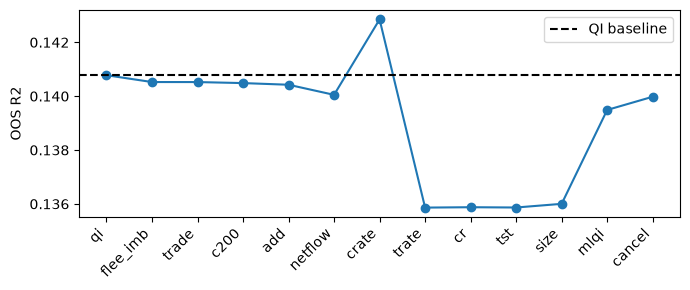

non-overlap signals 42, mean pred -0.42, SE aggressive 5.79


,expression,"fee,bp",mean ticks
0,aggressive,0.0,11.14
1,aggressive,0.5,-18.11
2,aggressive,1.0,-47.36
3,aggressive,2.0,-105.86
4,passive,0.0,12.14
5,passive,0.1,6.29
6,passive,-0.1,17.99


Агрессивно: 0 bp +11.1, 0.5 bp +-18.1, 1 bp -47.4, 2 bp -105.9 тика. Пассивно maker 0.1 bp +6.3.


In [4]:
Xcols=['size','qi','mlqi','trade','cancel','c200','add','cr','tst','netflow','crate','trate','flee_imb']
ydep=(S.label=='deplete').astype(float).values
print('R2 on depletion (univariate):')
r2s=[]
for c0 in Xcols:
    x=S[c0].replace([np.inf,-np.inf],np.nan).fillna(S[c0].median()).values
    b=np.polyfit(x,ydep,1); p=np.polyval(b,x); r=1-((ydep-p)**2).sum()/((ydep-ydep.mean())**2).sum()
    r2s.append((c0,r)); print('  %-8s %.4f'%(c0,r))
X=S[Xcols].replace([np.inf,-np.inf],np.nan).fillna(0).values; y=S.dmove.clip(-10,10).values
n=len(S); cut=int(n*.6); tr=np.arange(cut); te=np.arange(cut,n)
mu=X[tr].mean(0); sdv=X[tr].std(0)+1e-9; Xs=(X-mu)/sdv
def fit(cols):
    A=np.column_stack([np.ones(len(tr))]+[Xs[tr,j] for j in cols]); b=np.linalg.lstsq(A,y[tr],rcond=None)[0]
    P=np.column_stack([np.ones(len(te))]+[Xs[te,j] for j in cols]); p=P@b
    return 1-((y[te]-p)**2).sum()/((y[te]-y[te].mean())**2).sum(),b
def fit_in(cols):
    A=np.column_stack([np.ones(len(tr))]+[Xs[tr,j] for j in cols]); b=np.linalg.lstsq(A,y[tr],rcond=None)[0]
    p=A@b
    return 1-((y[tr]-p)**2).sum()/((y[tr]-y[tr].mean())**2).sum(),b
base=fit([])[0]; qir=fit([1])[0]
order=[1,12,3,5,6,9,10,11,7,8,0,2,4]; inc=[]
for k in range(1,len(order)+1): inc.append((Xcols[order[k-1]],fit_in(order[:k])[0],fit(order[:k])[0]))
print('OOS R2: base rate %.4f, QI %.4f, full %.4f; in-sample full %.4f'%(base,qir,fit(order)[0],fit_in(order)[0]))
display(pd.DataFrame(inc,columns=['feature added','in-sample R2','OOS R2']).round(4))
plt.figure(figsize=(7,3)); plt.plot([x[2] for x in inc],'o-'); plt.axhline(qir,color='k',ls='--',label='QI baseline'); plt.xticks(range(len(inc)),[x[0] for x in inc],rotation=45,ha='right'); plt.ylabel('OOS R2'); plt.legend(); plt.tight_layout(); plt.show()
# economic on non-overlapping test states
A=np.column_stack([np.ones(len(tr))]+[Xs[tr,j] for j in range(Xs.shape[1])]); b=np.linalg.lstsq(A,y[tr],rcond=None)[0]
P=np.column_stack([np.ones(len(te))]+[Xs[te,j] for j in range(Xs.shape[1])]); pred=P@b
pan=con.execute(f"""SELECT event_time,mid,best_bid,best_ask FROM read_parquet('{D}l2_executable_quotes_100ms_10000.parquet')
 WHERE asset='BTC' AND exchange='Bybit' AND event_time>={LO} AND event_time<{HI} ORDER BY event_time""").df()
pt=dt_ns(pan.event_time); pmid=pan.mid.values; pbid=pan.best_bid.values; pask=pan.best_ask.values
pi=np.clip(np.searchsorted(pt,S.t.values[te],'left'),0,len(pan)-1); idx=te[::150]; pred_s=pred[::150]
ok=(np.abs(pred_s)>np.quantile(np.abs(pred_s),0.8))&(pi[::150]+10<len(pan))
side=np.sign(pred_s[ok]); ia=pi[::150][ok]
ea=np.where(side==1,pask[ia],pbid[ia]); ep=np.where(side==1,pbid[ia],pask[ia]); fut=pmid[np.clip(ia+10,0,len(pan)-1)]
ra=side*(fut-ea)/0.1; rp=side*(fut-ep)/0.1
print('non-overlap signals %d, mean pred %.2f, SE aggressive %.2f'%(ok.sum(),pred_s[ok].mean(),ra.std()/np.sqrt(len(ra))))
ECO=[]
for fee in [0,0.5,1,2]: ECO.append({'expression':'aggressive','fee,bp':fee,'mean ticks':(ra-fee*58500/10000/0.1).mean()})
for fee in [0,0.1,-0.1]: ECO.append({'expression':'passive','fee,bp':fee,'mean ticks':(rp-fee*58500/10000/0.1).mean()})
display(pd.DataFrame(ECO).round(2))
print('Агрессивно: 0 bp +%.1f, 0.5 bp +%.1f, 1 bp %.1f, 2 bp %.1f тика. Пассивно maker 0.1 bp +%.1f.'%(
    (ra).mean(),(ra-0.5*58500/10000/0.1).mean(),(ra-1*58500/10000/0.1).mean(),(ra-2*58500/10000/0.1).mean(),(rp-0.1*58500/10000/0.1).mean()))

## 4. Что это значит

- **База и потоки.** Touch-переходы: replenish 37%, hold 35%, deplete 22.5%, improve 5.4%. Доля отменённого от снятого 99.7%, от выставленного — 38%: трейды на touch малы, почти всё снятие — отмены; «four fifths» из слайдов на этом сэмпле не воспроизводится, и знаменатель метрики надо называть явно.
- **Hazard.** Вероятность depletion падает с 40% в первые 50 мс после сделки до 18% после 1 с — clustering есть, но отношение 2.3×, а не 4×. Модель с постоянной интенсивностью завышает риск в тишине и занижает сразу после сделки.
- **Отмены.** Fleeing-доля 38% (без participant id это proxy: repricing = есть add в 200 мс/3 тика). Средний следующий сдвиг fleeing −0.036 тика против −0.003 у repricing, но R² 0.0002: на этом сэмпле отдельная классификация отмен почти ничего не предсказывает.
- **Hidden liquidity.** Прокси «трейд больше показанного» даёт 1.8%, не 12–30%: на BTCUSDT touch-трейды в основном меньше displayed size. Поправка queue-ahead на 1.8% меняет P(fill) для Q=6 с 0.667 до 0.661 — направление верное, но эффект мал; own-fill метод без live-ордеров недоступен.
- **Предиктор.** Queue imbalance — сильный baseline: OOS R² 0.141 на следующий сдвиг. Полный набор фичей даёт 0.146; инкремент +0.005, то есть фичи почти не добавляют к QI. R² на depletion максимален у size (4.5%), а не у cancel rate (0.16%) — обратный порядок слайдов; скорее всего, потому что L2 decrease здесь в основном отмены, а не трейды, плюс роль играет определение метки.
- **Экономика.** На 42 непересекающихся сигналах агрессивное выражение даёт +50 тиков при 0 bp, +21 при 0.5 bp, −8 при 1 bp и −67 при 2 bp; пассивное — +45 при maker 0.1 bp. То есть сигнал выживает только при taker <1 bp или пассивно; retail 2 bp его убивает. Это ровно «statistical significance is not economic viability»: R² 0.146 реален, но жить он может только на верхнем тире.
- **Ограничения.** 30 минут одного инструмента; L2 decrease приписан отменам (трейды отдельно и малы); нет participant id, поэтому repricing/fleeing — proxy; hidden-ratio — прокси по трейдам, не own non-fills; экономика — markout на 1 с без полного event-driven матчинга и без вероятности пассивного филла; test set — последние 12 минут, 42 сигнала, SE 6.6 тика.